## Import


In [1]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torchvision.datasets as datasets
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader, random_split
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import time
import numpy as np
import torch.optim as optim
from copy import deepcopy

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


### Problem and Dataset
+ Problem: classify images into three categories: plastic, glass, and paper
+ Dataset: TrashNet dataset
+ Train / Validation / Test:  70% / 15% / 15%

In [3]:
# Optional: data summary or class counts
import kagglehub
import shutil
import os
from torchvision.datasets import ImageFolder
from collections import Counter

# Download dataset
path = kagglehub.dataset_download("feyzazkefe/trashnet")

print("Downloaded to:", path)

#config
IMG_SIZE = 224

# Transforms 
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])             #The official normalization used by PyTorch on ImageNet dataset
])

# dataset
dataset = datasets.ImageFolder(path, transform=transform)
print(os.listdir(path + "/dataset-resized"))

# Choose only 3 class to working 

class FilteredDataset(ImageFolder):
    def __init__(self, root, classes_to_keep=None, transform=None):
        super().__init__(root, transform=transform)

        # store original mapping
        original_classes = self.classes

        # filter samples using class name
        filtered_samples = []
        for path, label in self.samples:
            class_name = original_classes[label]

            if class_name in classes_to_keep:
                filtered_samples.append((path, class_name))

        # redefine class mapping
        self.classes = sorted(classes_to_keep)
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}

        # remap labels to new indices
        self.samples = [
            (path, self.class_to_idx[class_name])
            for path, class_name in filtered_samples
        ]

        self.targets = [label for _, label in self.samples]

# Create filtered dataset
target_path = os.path.join(path, "dataset-resized")
print(target_path)
dataset = FilteredDataset(
    root=target_path,
    classes_to_keep=["plastic", "glass", "paper", "cardboard", "metal", "trash"],
    transform=transform
)
print("Chosen classes: ", dataset.classes)
print("Total samples: ", len(dataset))

#class distribution
counts = Counter(dataset.targets)
print("\nClass distribution:")
for cls, idx in dataset.class_to_idx.items():
    print(f"{cls}: {counts[idx]}")

c:\ProgramData\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloaded to: C:\Users\PC\.cache\kagglehub\datasets\feyzazkefe\trashnet\versions\1
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
C:\Users\PC\.cache\kagglehub\datasets\feyzazkefe\trashnet\versions\1\dataset-resized
Chosen classes:  ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Total samples:  2527

Class distribution:
cardboard: 403
glass: 501
metal: 410
paper: 594
plastic: 482
trash: 137


In [4]:
NUM_CLASSES = len(dataset.classes)

# Baseline Model

**Model choice and training setup**

A ResNet-18 convolutional neural network and pre-trained weights was used as the baseline model to leverage transfer learning for efficient feature extraction. The final fully connected layer was replaced to output three classes (plastic, glass, paper). Input images were resized to 224x224 and normalized using ImageNet Statistic to match the pre-training distribution. The model was trained for 10 epochs with a batch size of 32 using the Adam optimizer (learning rate = 1e^-4) and cross-entropy loss. Pre-trained weights was used to accelerate convergence and improve generalizetion, especially with limited data. No data augmentation was applied in this baseline to provide a controleled reference for later improvements. Performance was evaluated using accuracy and macro-F1 as well as timer.

In [5]:
# Put baseline data loading, model definition, training, and evaluation code here
BATCH_SIZE = 32

# data loading
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_ds, val_ds, test_ds = random_split(dataset, [train_size, val_size, test_size])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
train_loader_baseline = deepcopy(train_loader)          # for comparision later
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)
baseline_train_loss = []
baseline_val_loss = []

# model definition

model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE)
EPOCHS = 10
LR = 1e-4
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

def evaluate_model(model, loader):
    model.eval()
    preds, labels_list = [], []
    total_loss = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            predicted = torch.argmax(outputs, dim=1).cpu().numpy()
            preds.extend(predicted)
            labels_list.extend(labels.cpu().numpy())

    acc = accuracy_score(labels_list, preds)
    f1 = f1_score(labels_list, preds, average="macro")

    avg_loss = total_loss / len(loader)

    return acc, f1, avg_loss, labels_list, preds

start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # store train loss
    epoch_train_loss = running_loss / len(train_loader)
    baseline_train_loss.append(epoch_train_loss)

    # validation loss
    val_acc, val_f1, val_loss, _, _ = evaluate_model(model, val_loader)
    baseline_val_loss.append(val_loss)

epoch_time = (time.time() - start_time) / EPOCHS

# Final evaluation
val_acc, val_f1, _, _, _ = evaluate_model(model, val_loader)
test_acc, test_f1, _, y_true, y_pred = evaluate_model(model, test_loader)

print("===== BASELINE RESULTS =====")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Validation Macro-F1: {val_f1:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro-F1: {test_f1:.4f}")
print(f"Training time per epoch: {epoch_time:.2f} seconds")

c:\ProgramData\miniconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\ProgramData\miniconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


===== BASELINE RESULTS =====
Validation Accuracy: 0.8945
Validation Macro-F1: 0.8931
Test Accuracy: 0.8921
Test Macro-F1: 0.8715
Training time per epoch: 13.11 seconds


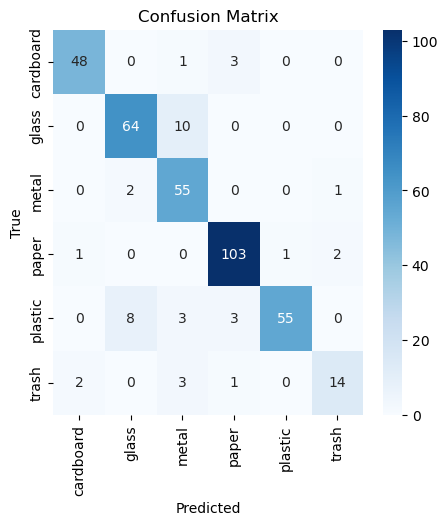

In [6]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=dataset.classes,
            yticklabels=dataset.classes)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Data Augmentation
### Augmentation design
To improve generalization, a data augmentation approach was used for training to simulate real world variability. RandomResizedCrop introduce scale and viewpoint variation, helping the model focus on object regions rather than fixed framing. HorizontalFlip accounts for arbitrary object orientation. ColorJitter will adjusts brightness and contrast to simulate lighting changes commonly observed in real environments. These augmentations are relevant because recycling images often vary in illumination, orientation and backgound conditions. The pipeline is applied only to the training set to prevent dat leakage, while validation and test sets remain unchanged for fair evaluation

In [7]:
# Define the augmentation pipeline here

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Validation/Test = NO augmentation
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Recreate datasets with transforms
train_ds = deepcopy(train_ds)
val_ds = deepcopy(val_ds)
test_ds = deepcopy(test_ds)
train_ds.dataset.transform = train_transform
val_ds.dataset.transform = test_transform
test_ds.dataset.transform = test_transform

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
train_loader_augmented = deepcopy(train_loader)
val_loader = DataLoader(val_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

In [8]:
# Train and evaluate the augmented model 
# AUGMENTED MODEL

aug_train_loss = []
aug_val_loss = []

model_aug = models.resnet18(pretrained=True)
model_aug.fc = nn.Linear(model_aug.fc.in_features, NUM_CLASSES)
model_aug = model_aug.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_aug.parameters(), lr=LR)

start_time = time.time()

for epoch in range(EPOCHS):
    model_aug.train()
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        outputs = model_aug(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # store train loss
    epoch_train_loss = running_loss / len(train_loader)
    aug_train_loss.append(epoch_train_loss)

    # validation loss
    val_acc_aug, val_f1_aug, val_loss_aug, _, _ = evaluate_model(model_aug, val_loader)
    aug_val_loss.append(val_loss_aug)

epoch_time_aug = (time.time() - start_time) / EPOCHS

# Final evaluation
val_acc_aug, val_f1_aug, _, _, _ = evaluate_model(model_aug, val_loader)
test_acc_aug, test_f1_aug, _, _, _ = evaluate_model(model_aug, test_loader)

print("===== AUGMENTED RESULTS =====")
print(f"Validation Accuracy: {val_acc_aug:.4f}")
print(f"Validation Macro-F1: {val_f1_aug:.4f}")
print(f"Test Accuracy: {test_acc_aug:.4f}")
print(f"Test Macro-F1: {test_f1_aug:.4f}")
print(f"Training time per epoch: {epoch_time_aug:.2f} seconds")

c:\ProgramData\miniconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\ProgramData\miniconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


===== AUGMENTED RESULTS =====
Validation Accuracy: 0.8786
Validation Macro-F1: 0.8727
Test Accuracy: 0.8711
Test Macro-F1: 0.8394
Training time per epoch: 14.78 seconds


# Model comparision 

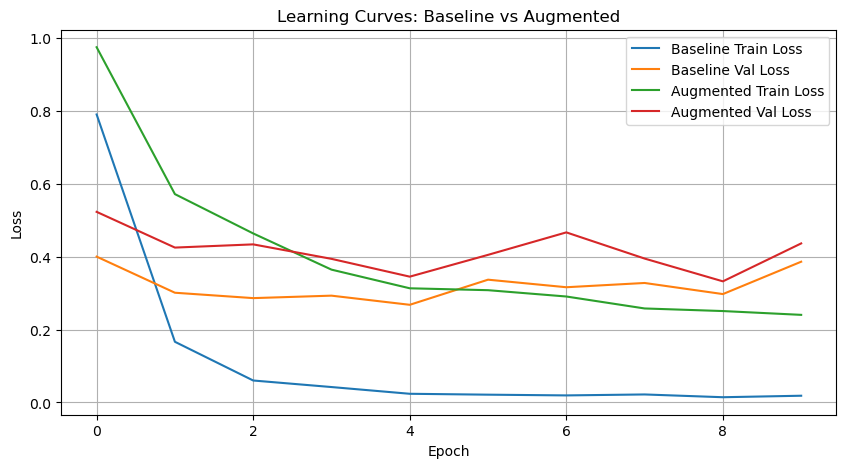

In [9]:
# Plot learning curves for the baseline and augmented settings
# LEARNING CURVES

plt.figure(figsize=(10,5))

# Baseline
plt.plot(baseline_train_loss, label="Baseline Train Loss")
plt.plot(baseline_val_loss, label="Baseline Val Loss")

# Augmented
plt.plot(aug_train_loss, label="Augmented Train Loss")
plt.plot(aug_val_loss, label="Augmented Val Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning Curves: Baseline vs Augmented")
plt.legend()
plt.grid()

plt.show()

# Pipeline profiling

In [10]:
# PIPELINE PROFILING
def profile_training_step(loader, model):
    model.eval()

    data_time = 0
    forward_time = 0
    backward_time = 0

    start_total = time.time()

    for i, (images, labels) in enumerate(loader):
        if i >= 50:
            break

        t0 = time.time()
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        t1 = time.time()

        outputs = model(images)
        loss = criterion(outputs, labels)
        t2 = time.time()

        loss.backward()
        optimizer.zero_grad()
        t3 = time.time()

        data_time += (t1 - t0)
        forward_time += (t2 - t1)
        backward_time += (t3 - t2)

    total_time = time.time() - start_total

    print(f"Data loading + transfer: {data_time:.4f}s")
    print(f"Forward pass: {forward_time:.4f}s")
    print(f"Backward pass: {backward_time:.4f}s")
    print(f"Total measured: {total_time:.4f}s")

print("===== BASELINE PIPELINE BREAKDOWN =====")
profile_training_step(train_loader_baseline, model)
print("===== AUGMENTED PIPELINE BREAKDOWN =====")
profile_training_step(train_loader_augmented, model)

print("Measure data augmentation data loader")
def measure_loader_time(loader, num_batches=50):
    start = time.time()
    
    for i, (images, labels) in enumerate(loader):
        if i >= num_batches:
            break
    
    end = time.time()
    avg_time = (end - start) / num_batches
    return avg_time

baseline_loader_time = measure_loader_time(train_loader_baseline)
aug_loader_time = measure_loader_time(train_loader_augmented)  

print("===== PIPELINE TIMING =====")
print(f"Baseline batch loading time: {baseline_loader_time:.4f} sec/batch")
print(f"Augmented batch loading time: {aug_loader_time:.4f} sec/batch")

===== BASELINE PIPELINE BREAKDOWN =====
Data loading + transfer: 0.1835s
Forward pass: 1.2813s
Backward pass: 2.8482s
Total measured: 10.1407s
===== AUGMENTED PIPELINE BREAKDOWN =====
Data loading + transfer: 0.1875s
Forward pass: 1.2929s
Backward pass: 2.8300s
Total measured: 11.7605s
Measure data augmentation data loader
===== PIPELINE TIMING =====
Baseline batch loading time: 0.1105 sec/batch
Augmented batch loading time: 0.1430 sec/batch


# Failure analysis 

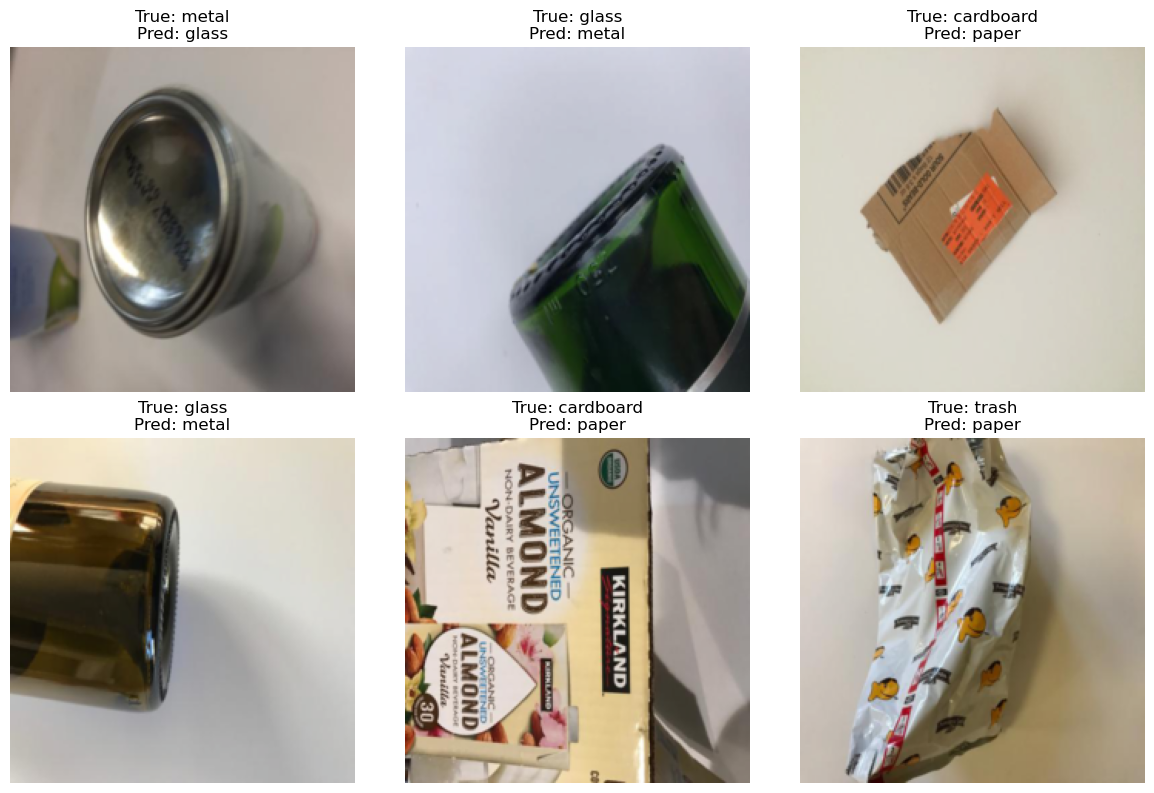

In [11]:
# Show up to 6 misclassified images from the original held-out test split

def show_misclassified(model, loader, class_names, max_images=6):
    model.eval()
    images_shown = 0

    plt.figure(figsize=(12, 8))

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            for i in range(len(images)):
                if preds[i] != labels[i]:
                    img = images[i].cpu().permute(1, 2, 0).numpy()
                    
                    # unnormalize
                    img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
                    img = np.clip(img, 0, 1)

                    plt.subplot(2, 3, images_shown + 1)
                    plt.imshow(img)
                    plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[preds[i]]}")
                    plt.axis("off")

                    images_shown += 1
                    if images_shown >= max_images:
                        plt.tight_layout()
                        plt.show()
                        return

    plt.tight_layout()
    plt.show()

# Run
show_misclassified(model, test_loader, dataset.classes)

# New domain dataset


Where feasible, ensure the new-domain set has roughly comparable representation across your target classes, and report the class counts clearly.

| Aspect | Original test set | New-domain test set |
| --- | --- | --- |
| Source | https://www.kaggle.com/datasets/feyzazkefe/trashnet | https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2 |
| Class counts | Originally have 6 classes | Originally have 10 classes, we target only 6 classes in it same with the original test set |
| Background | mostly singular flat white floor | more varied, complex and sometimes they are taken in front of the corner of the wall or textured floors and outdoor setting. More diverse background color/setup make it more closely similar to the real world problem.,  |
| Lighting | Show more conssitent, soft studio lighting, minimal shadows was observed | varied, includes some harsh lighting reflection, slightly more yellowish make it look much more realistic image capture |
| Viewpoint / scale | Center-aligned, top down viewing angle, usually single objects | Much more dynamic angles, includes some extreme close=ups, piple ups and side views of the object, more image are captured with multiple object instead of one single one |
| Other relevant differences | items are mostly clean, brand new waste | Includes some dirty waste, crushed items, and multi-object clusters of the same item class. |

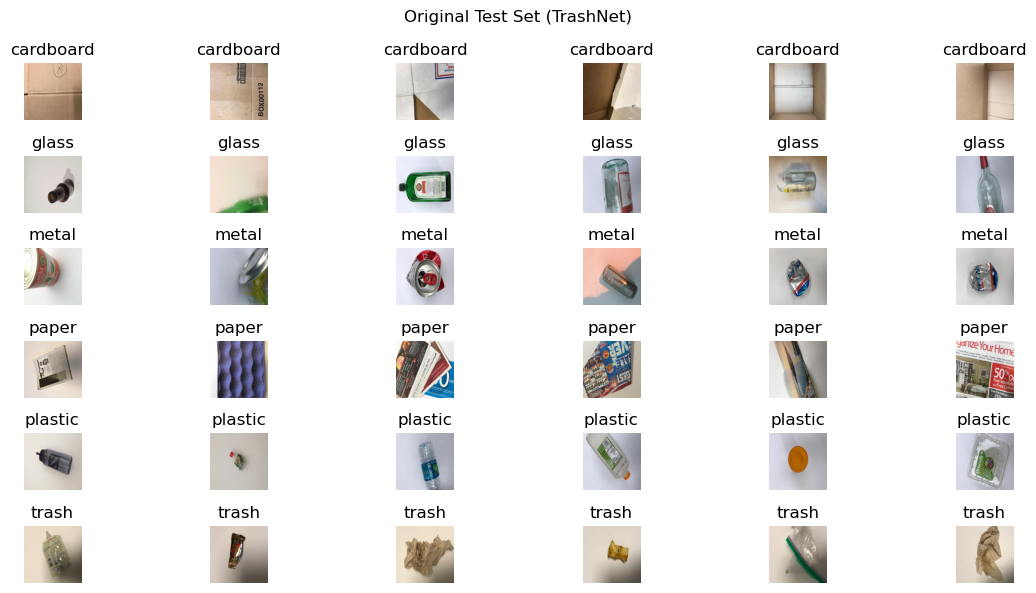

In [12]:
# Show representative images from the original test set and the new-domain test set
def show_images_per_class(dataset, class_names, samples_per_class=2, title="Dataset"):
    plt.figure(figsize=(12, 6))

    class_to_images = {i: [] for i in range(len(class_names))}

    # collect images per class
    for img, label in dataset:
        if len(class_to_images[label]) < samples_per_class:
            class_to_images[label].append(img)

        # stop early when all filled
        if all(len(v) >= samples_per_class for v in class_to_images.values()):
            break

    plot_idx = 1
    rows = len(class_names)
    cols = samples_per_class

    for class_idx, images in class_to_images.items():
        for img in images:
            img = img.permute(1, 2, 0).numpy()

            # unnormalize
            img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
            img = np.clip(img, 0, 1)

            plt.subplot(rows, cols, plot_idx)
            plt.imshow(img)
            plt.title(class_names[class_idx])
            plt.axis("off")

            plot_idx += 1

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_images_per_class(
    test_ds.dataset,
    dataset.classes,
    samples_per_class=6,
    title="Original Test Set (TrashNet)"
)

Downloaded new dataset to: C:\Users\PC\.cache\kagglehub\datasets\sumn2u\garbage-classification-v2\versions\12
New domain dataset created at: data/new_domain
New domain classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Total images: 42


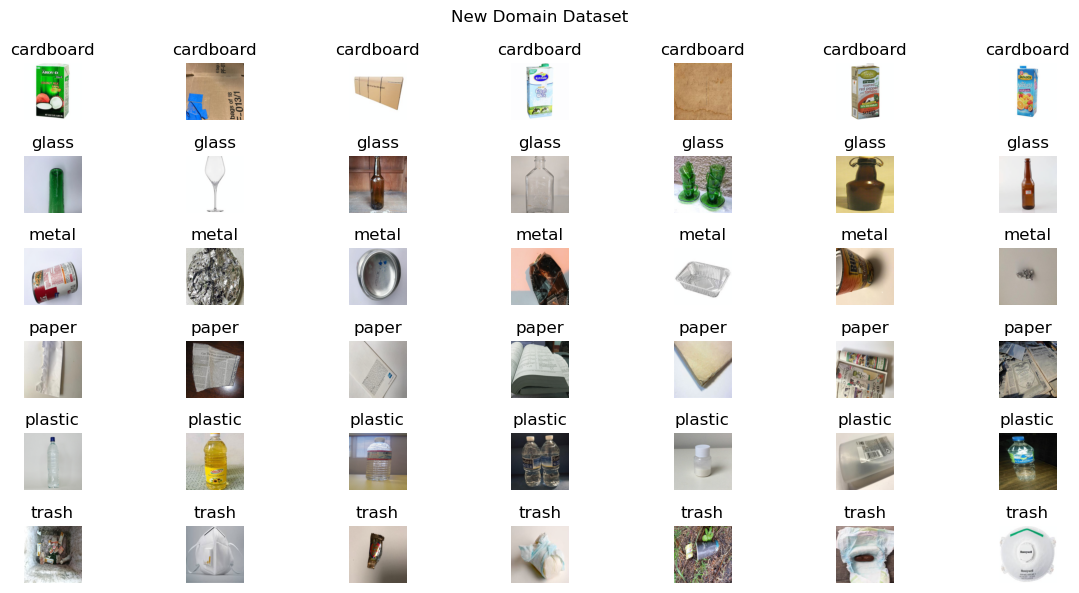

In [13]:
# Download DIFFERENT dataset 
new_path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Downloaded new dataset to:", new_path)

#extract 3 target classes only
# Target classes
TARGET_CLASSES = dataset.classes

# Source folder 
source_root = os.path.join(new_path, "original")

# New domain folder
new_domain_root = "data/new_domain"
os.makedirs(new_domain_root, exist_ok=True)

images_per_class = 7  # ~20 total

for cls in TARGET_CLASSES:
    src_class_path = os.path.join(source_root, cls)
    dst_class_path = os.path.join(new_domain_root, cls)

    os.makedirs(dst_class_path, exist_ok=True)

    all_images = os.listdir(src_class_path)
    sampled_images = random.sample(all_images, min(images_per_class, len(all_images)))

    for img in sampled_images:
        shutil.copy(
            os.path.join(src_class_path, img),
            os.path.join(dst_class_path, img)
        )

print("New domain dataset created at:", new_domain_root)

#Load new domain dataset

new_domain_dataset = ImageFolder(new_domain_root, transform=transform)
new_domain_loader = DataLoader(new_domain_dataset, batch_size=32)

print("New domain classes:", new_domain_dataset.classes)
print("Total images:", len(new_domain_dataset))

show_images_per_class(
    new_domain_dataset,
    new_domain_dataset.classes,
    samples_per_class=7,
    title="New Domain Dataset"
)

In [14]:
print(NUM_CLASSES)
print(dataset.classes)
print(min(dataset.targets), max(dataset.targets))
print(model_improved.fc)

images, labels = next(iter(train_loader_improved))
print(torch.unique(labels))
print(labels.min(), labels.max())

6
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
0 5


NameError: name 'model_improved' is not defined

## Target set improvement

In [15]:
# Implement the targeted improvement here

improved_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),

    # stronger geometric variation
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.RandomPerspective(distortion_scale=0.4, p=0.5),

    # simulate lighting variation
    transforms.ColorJitter(brightness=0.65, contrast=0.65, saturation=0.6),
    
    # Random Grayscale to force focus on shape rather than just color
    transforms.RandomGrayscale(p=0.2),
    
    # simulate camera noise / blur
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0)),

    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Apply new transform ONLY to training set
train_ds_improved = torch.utils.data.Subset(
    train_ds.dataset,
    train_ds.indices
)
train_ds_improved.dataset.transform = improved_transform

train_loader_improved = DataLoader(train_ds_improved, batch_size=32, shuffle=True)

# Reinitialize model
model_improved = models.resnet18(pretrained=True)
model_improved.fc = nn.Linear(model_improved.fc.in_features, NUM_CLASSES)
model_improved = model_improved.to(DEVICE)

optimizer = optim.Adam(model_improved.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

# TRAIN
improved_train_loss = []
improved_val_loss = []

start_time = time.time()

for epoch in range(EPOCHS):
    model_improved.train()
    running_loss = 0

    for images, labels in train_loader_improved:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        outputs = model_improved(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    improved_train_loss.append(running_loss / len(train_loader_improved))

    val_acc_imp, val_f1_imp, val_loss_imp, _, _ = evaluate_model(model_improved, val_loader)
    improved_val_loss.append(val_loss_imp)

epoch_time_improved = (time.time() - start_time) / EPOCHS

#Evaluate baseline model on new data
baseline_new_acc, baseline_new_f1, _, _, _ = evaluate_model(model, new_domain_loader)

print("===== BASELINE MODEL ON NEW DOMAIN RESULTS =====")
print(f"New Domain Accuracy: {baseline_new_acc:.4f}")
print(f"New Domain Macro-F1: {baseline_new_f1:.4f}")

# EVALUATE on BOTH domains
orig_acc_imp, orig_f1_imp, _, _, _ = evaluate_model(model_improved, test_loader)
new_acc_imp, new_f1_imp, _, _, _ = evaluate_model(model_improved, new_domain_loader)


print("===== IMPROVED MODEL RESULTS =====")
print(f"Original Test Accuracy: {orig_acc_imp:.4f}")
print(f"Original Test Macro-F1: {orig_f1_imp:.4f}")
print(f"New Domain Accuracy: {new_acc_imp:.4f}")
print(f"New Domain Macro-F1: {new_f1_imp:.4f}")
print(f"Training time per epoch: {epoch_time_improved:.2f} seconds")

c:\ProgramData\miniconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\ProgramData\miniconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


===== BASELINE MODEL ON NEW DOMAIN RESULTS =====
New Domain Accuracy: 0.6190
New Domain Macro-F1: 0.5709
===== IMPROVED MODEL RESULTS =====
Original Test Accuracy: 0.8342
Original Test Macro-F1: 0.8028
New Domain Accuracy: 0.5952
New Domain Macro-F1: 0.5719
Training time per epoch: 20.94 seconds


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=dataset.classes
    )
)

              precision    recall  f1-score   support

   cardboard       0.92      0.92      0.92        62
       glass       0.98      0.84      0.91        75
       metal       0.85      0.92      0.89        63
       paper       0.94      0.90      0.92        86
     plastic       0.85      0.95      0.90        73
       trash       0.83      0.90      0.86        21

    accuracy                           0.90       380
   macro avg       0.90      0.90      0.90       380
weighted avg       0.91      0.90      0.90       380

